# 112 Boombox → hybrid: what changed and what each change was worth

The original **Boombox** (src6, run `s6-gastro-plastic-cardboard-3k`) vs the current best **hybrid** (`s8-mag-nopose-imom-*`; code in `src9/arch/boombox.py` and `src9/arch/hybrid.py`).
1. every difference, one line each
2. the lineage: each feature in the order we added it, scored on its own saved eval outputs (`src8/score.py`, iou@0.08, ep500)
3. the clean ablations and the like-for-like end-to-end pair

No training here: every number comes from existing runs.

## 1 Differences, Boombox → hybrid

| group | Boombox (s6) | hybrid (s8-mag-nopose-imom) | why |
|---|---|---|---|
| input | \|FFT\| of the whole capture, **hann** window | \|FFT\|, **tukey** window | hann scales frequency gain and costs SNR in the sweep's edge bands (nb100) |
| input | magnitude, std norm | magnitude, std norm (+ **per-box standardization**: running mean/std per box, laser, bin, axis) | the object is a small change to the box's own spectrum; box norm takes out the box |
| encoder, frequency | 4 stride-4 convs (32→256 ch), then a **mean** over the leftover frequency | 3 stride-4 convs (+ log f as an input channel) → **19 band tokens** (~49 Hz) per laser | the model reads exact peak positions (a 9 Hz roll: .30 → .06); a mean loses them |
| encoder, embeddings | none | learned per-laser embedding + Fourier features of the laser's (row, col), band embedding, **box embedding** | laser identity and placement matter (laser shuffle → .02); continuous positions let laser jitter work |
| encoder, pooling | mean over frequency | **gated flatten** per laser: a softmax gate per band, bands concatenated → Linear | the v1 ModalFormer's mean-pooling fit a constant mask |
| encoder, lasers | 3 convs on the 10×10 laser grid (10→5→3→1) | **2 transformer blocks** over the 100 laser tokens → **flatten** → Linear (not a mean) | every laser talks to every laser; flatten keeps which laser said what |
| decoder | 512×4×4 seed, 4 two-branch upsamplings to 64×64, 3-conv head, **1 channel** | the same decoder, **2 channels** (mask + outline) | unchanged except the outline channel |
| loss | mask BCE + aux heads (.1 object, .1 count, 1 com, .1 area, .1 box) | same + **edge** (BCE-dice on a 1 px outline) + **per-instance moments** (area, centroid, covariance per object) + **orientation** head | shapes, sizes and rotation get their own signal; per-instance moments keep two objects apart |
| augmentation | none | **speaker gain** (random smooth log-gain over frequency, knots every 20 Hz, rms .35) + **laser jitter** (grid shifted U(−.5, .5) cells) | unseen speakers multiply every laser by one S(f); jitter stops reading exact laser placement |
| pose branch | — | tried (STN canonical mask + angle), then **removed** | it fixed rotation but made the model draw one object |
| training | lr 1e-4, cosine, 100-ep warmup, bs 1024, **3000 ep**, eval every 25 | lr 1e-4, cosine, 50-ep warmup, bs 1024 (microbatch 512), **500 ep**, eval every 50 | rankings at ep500 ≈ ep1000 |
| size | 35.2M params | 34.5M params | about the same size |

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path('/home/ethantu/workspace/good-vibrations')
sys.path.insert(0, str(ROOT / 'src8'))
from score import per_sample, summarize          # cached per (run, epoch) in runs/<run>/scores
from multi_object import scenes

T = 0.08; I = f'iou@{T}'
def metrics(run, ep=500):
    df = per_sample(run, ep, [T])
    s, sp = summarize(df, [I, f'orient_err@{T}'])
    split = lambda m: sp.loc[m, I].mean()
    sc = scenes(run, ep)
    return dict(CORE=s.loc['CORE', I], HARD=s.loc['HARD-kept', I], deg=s.loc['HARD-kept', f'orient_err@{T}'],
                both=sc.both.mean(), spk=split(sp.split.str.endswith('unseen-speaker-unseen')),
                laser=split(sp.split.str.contains('laser')), ALL=s.loc['ALL', I])

## 2 The lineage, in the order we added things

Each step is the run that added that feature to the step before it. **\*** = not a clean one-change step (the label says what else changed).
- Step 0 is the Boombox at ep500 of its 3000-ep schedule (src6's own split, eval every 25 ep). Its ep3000 score is the dashed tick.
- Steps 1–10 are all on the original split (`gastronorm_plastic_cardboard`) at ep500.
- The last two bars are split changes, not features (wedge holds out 30–60° rotated soap, region holds out a floor block). They're shown in grey so the drop isn't read as a regression.

**Metrics:**
- CORE: 4 base objects × 3 boxes.
- HARD: the cardboard rotated soap, outside the wedge.
- both found: two-object scenes where both objects are found.
- unseen speaker: speaker 4.
- ALL: the mean over every non-control split.

In [2]:
STEPS = [  # (label, run, epoch, split, clean)
    ('Boombox (s6)',                       's6-gastro-plastic-cardboard-3k', 500, 'src6',   True),
    ('tukey window,\n500-ep schedule*',    's8-conv-mag-r2-500ep',           500, 'orig',   False),
    ('log power\n(the s7 target)',          's8-conv-logpower-500ep',         500, 'orig',   True),
    ('ModalFormer encoder\n+ box norm*',    's8-hybrid-base-500ep',           500, 'orig',   False),
    ('pose branch\n+ orient loss*',         's8-hybrid-posesum-500ep',        500, 'orig',   False),
    ('edge + moment\nlosses*',              's8-posesum-contour-500ep',       500, 'orig',   False),
    ('laser jitter',                        's8-best-jitter-500ep',           500, 'orig',   True),
    ('speaker gain',                        's8-best-spkgain-500ep',          500, 'orig',   True),
    ('magnitude\n(back from log power)',    's8-best-mag-500ep',              500, 'orig',   True),
    ('remove pose\nbranch',                 's8-mag-nopose-r2-500ep',         500, 'orig',   True),
    ('per-instance\nmoments',               's8-mag-nopose-imom-r2-500ep',    500, 'orig',   True),
    ('wedge split',                         's8-mag-nopose-imom-w-500ep',     500, 'wedge',  True),
    ('region split',                        's8-mag-nopose-imom-region-500ep',500, 'region', True),
]
lin = pd.DataFrame([dict(label=l, run=r, epoch=e, split=s, clean=c, **metrics(r, e)) for l, r, e, s, c in STEPS])
s6_3k = metrics('s6-gastro-plastic-cardboard-3k', 3000)
lin.round(3)

,label,run,epoch,split,clean,CORE,HARD,deg,both,spk,laser,ALL
0,Boombox (s6),s6-gastro-plastic-cardboard-3k,500,src6,True,0.590,0.371,34.618,0.399,0.341,0.165,0.323
1,"tukey window,\n500-ep schedule*",s8-conv-mag-r2-500ep,500,orig,False,0.626,0.460,34.079,0.446,0.280,0.167,0.327
2,log power\n(the s7 target),s8-conv-logpower-500ep,500,orig,True,0.577,0.422,38.217,0.366,0.227,0.117,0.299
3,ModalFormer encoder\n+ box norm*,s8-hybrid-base-500ep,500,orig,False,0.643,0.531,31.308,0.452,0.227,0.145,0.336
4,pose branch\n+ orient loss*,s8-hybrid-posesum-500ep,500,orig,False,0.662,0.558,23.391,0.378,0.211,0.150,0.342
5,edge + moment\nlosses*,s8-posesum-contour-500ep,500,orig,False,0.688,0.584,19.187,0.372,0.226,0.117,0.355
6,laser jitter,s8-best-jitter-500ep,500,orig,True,0.705,0.615,17.549,0.006,0.244,0.174,0.367
7,speaker gain,s8-best-spkgain-500ep,500,orig,True,0.722,0.597,19.588,0.286,0.279,0.203,0.388
8,magnitude\n(back from log power),s8-best-mag-500ep,500,orig,True,0.738,0.594,18.175,0.360,0.355,0.215,0.399
9,remove pose\nbranch,s8-mag-nopose-r2-500ep,500,orig,True,0.738,0.590,28.577,0.714,0.390,0.219,0.412


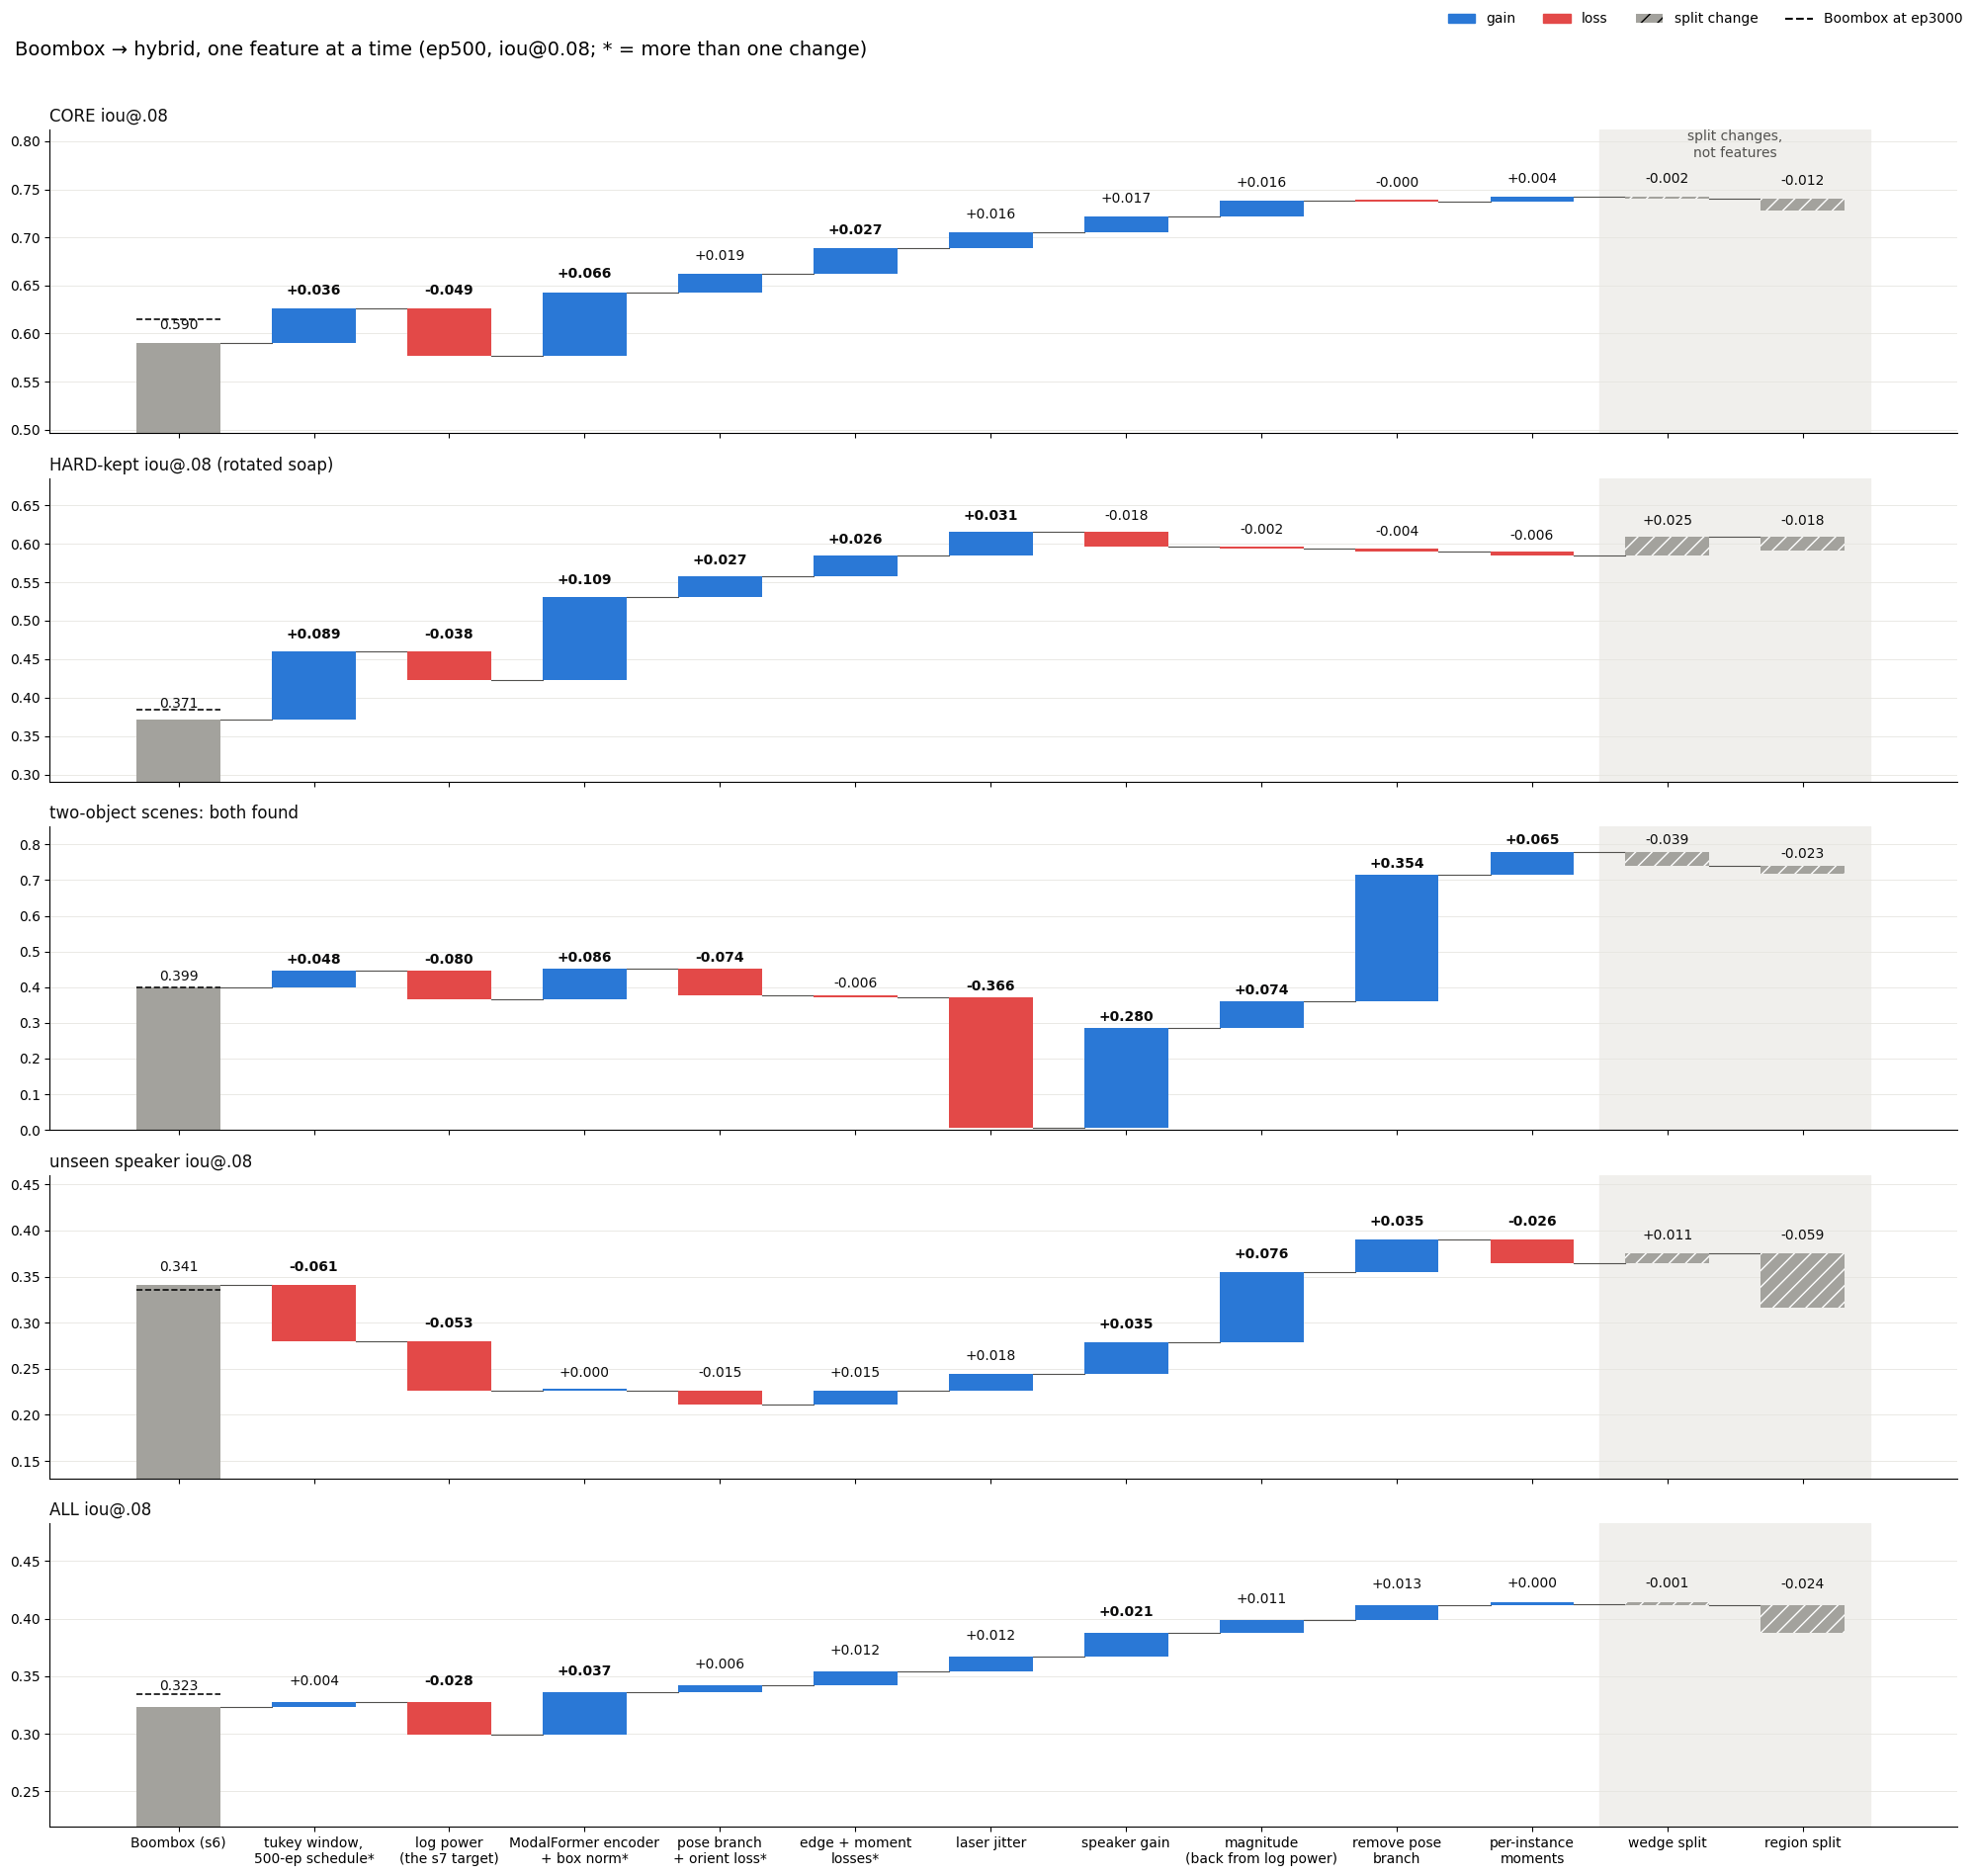

In [3]:
UP, DOWN, NEUTRAL, INK, MUTED = '#2a78d6', '#e34948', '#a3a29d', '#0b0b0b', '#52514e'
PANELS = [('CORE', 'CORE iou@.08'), ('HARD', 'HARD-kept iou@.08 (rotated soap)'), ('both', 'two-object scenes: both found'),
          ('spk', 'unseen speaker iou@.08'), ('ALL', 'ALL iou@.08')]
fig, axes = plt.subplots(len(PANELS), 1, figsize=(20, 19), sharex=True)
x = np.arange(len(lin))
for ax, (k, title) in zip(axes, PANELS):
    v = lin[k].to_numpy()
    for i in range(len(v)):
        split_step = lin.split[i] in ('wedge', 'region')
        if i == 0:
            ax.bar(i, v[0], width=0.62, color=NEUTRAL, zorder=2)
            ax.text(i, v[0] + 0.012, f'{v[0]:.3f}', ha='center', va='bottom', fontsize=10, color=INK)
            ax.hlines(s6_3k[k], i - 0.31, i + 0.31, colors=INK, linestyles='--', lw=1.2, zorder=3)
            continue
        d = v[i] - v[i - 1]
        lo, hi = sorted((v[i - 1], v[i]))
        ax.bar(i, max(hi - lo, 0.002), bottom=lo, width=0.62, color=NEUTRAL if split_step else (UP if d >= 0 else DOWN),
               hatch='//' if split_step else None, edgecolor='white', lw=0, zorder=2)
        ax.plot([i - 1 + 0.31, i - 0.31], [v[i - 1]] * 2, color=MUTED, lw=0.8, zorder=1)   # connector from the previous level
        ax.text(i, hi + 0.012, f'{d:+.3f}', ha='center', va='bottom', fontsize=10, color=INK, fontweight='bold' if abs(d) >= 0.02 and not split_step else 'normal')
    ax.set_title(title, loc='left', fontsize=12, color=INK)
    ax.set_ylim(min(v.min(), s6_3k[k]) - 0.08 if k != 'both' else 0, max(v.max(), s6_3k[k]) + 0.07)
    ax.grid(axis='y', color='#e6e5e0', lw=0.6, zorder=0); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.axvspan(10.5, 12.5, color='#f0efec', zorder=0)
axes[-1].set_xticks(x, lin.label, fontsize=10)
axes[0].text(11.5, axes[0].get_ylim()[1], 'split changes,\nnot features', ha='center', va='top', fontsize=10, color=MUTED)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig.legend(handles=[Patch(color=UP, label='gain'), Patch(color=DOWN, label='loss'), Patch(facecolor=NEUTRAL, hatch='//', label='split change'),
                    Line2D([], [], color=INK, ls='--', label='Boombox at ep3000')], loc='upper right', ncol=4, frameon=False, fontsize=10)
fig.suptitle('Boombox → hybrid, one feature at a time (ep500, iou@0.08; * = more than one change)', x=0.01, ha='left', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## 3 Clean comparisons

**(a) End to end, like for like.** The Boombox recipe (`s8-s6-region`: src8's conv encoder with its default flags, i.e. src6's model and losses, hann, magnitude) vs the hybrid, both on the region split at ep500, with the same eval samples.

**(b) Clean ablations of the plain hybrid** on the wedge split, ep500:
- `hybrid-mag-r2` is the plain hybrid: mask BCE, aux heads, no edge, moments, augs or pose. `nopose-imom-w` adds the whole recipe on top of it.
- `nolaser-r2` and `nobn-r2` were trained on **log power**, not magnitude. So their clean reference is `hybrid-base` (log power, plain, original split), not `hybrid-mag-r2`.
- That correction matters: src8/EXPERIMENTS.md compares them to `hybrid-mag-r2` and so mixes the signal change into the box-norm and laser-block numbers.

In [4]:
PAIR = {'Boombox recipe (s8-s6-region)': metrics('s8-s6-region-500ep'), 'hybrid (s8-mag-nopose-imom-region)': metrics('s8-mag-nopose-imom-region-500ep')}
pair = pd.DataFrame(PAIR).T[['CORE', 'HARD', 'both', 'spk', 'laser', 'ALL']]
ABL = [  # (label, run with the feature, run without it)
    ('whole recipe (edge, moments, orient,\njitter, speaker gain) on the plain hybrid', 's8-mag-nopose-imom-w-500ep', 's8-hybrid-mag-r2-500ep'),
    ('magnitude vs log power, plain hybrid*', 's8-hybrid-mag-r2-500ep', 's8-hybrid-base-500ep'),
    ('box norm, plain hybrid on log power*', 's8-hybrid-base-500ep', 's8-hybrid-nobn-r2-500ep'),
    ('laser transformer blocks, plain hybrid on log power*', 's8-hybrid-base-500ep', 's8-hybrid-nolaser-r2-500ep'),
    ('magnitude vs log power, conv encoder', 's8-conv-mag-r2-500ep', 's8-conv-logpower-500ep'),
]
cache = {}
M = lambda r: cache.setdefault(r, metrics(r))
abl = pd.DataFrame([{'change': l, **{k: M(a)[k] - M(b)[k] for k in ['CORE', 'HARD', 'both', 'spk', 'ALL']}} for l, a, b in ABL]).set_index('change')
display(pair.round(3)); display(abl.round(3))

,CORE,HARD,both,spk,laser,ALL
Boombox recipe (s8-s6-region),0.590,0.332,0.342,0.251,0.121,0.286
hybrid (s8-mag-nopose-imom-region),0.728,0.591,0.718,0.316,0.194,0.387


,CORE,HARD,both,spk,ALL
change,,,,,
"whole recipe (edge, moments, orient,\njitter, speaker gain) on the plain hybrid",0.081,0.055,0.223,0.111,0.064
"magnitude vs log power, plain hybrid*",0.017,0.023,0.065,0.037,0.012
"box norm, plain hybrid on log power*",0.027,0.072,0.071,-0.001,0.018
"laser transformer blocks, plain hybrid on log power*",-0.004,0.011,-0.045,-0.026,-0.003
"magnitude vs log power, conv encoder",0.049,0.038,0.080,0.053,0.028


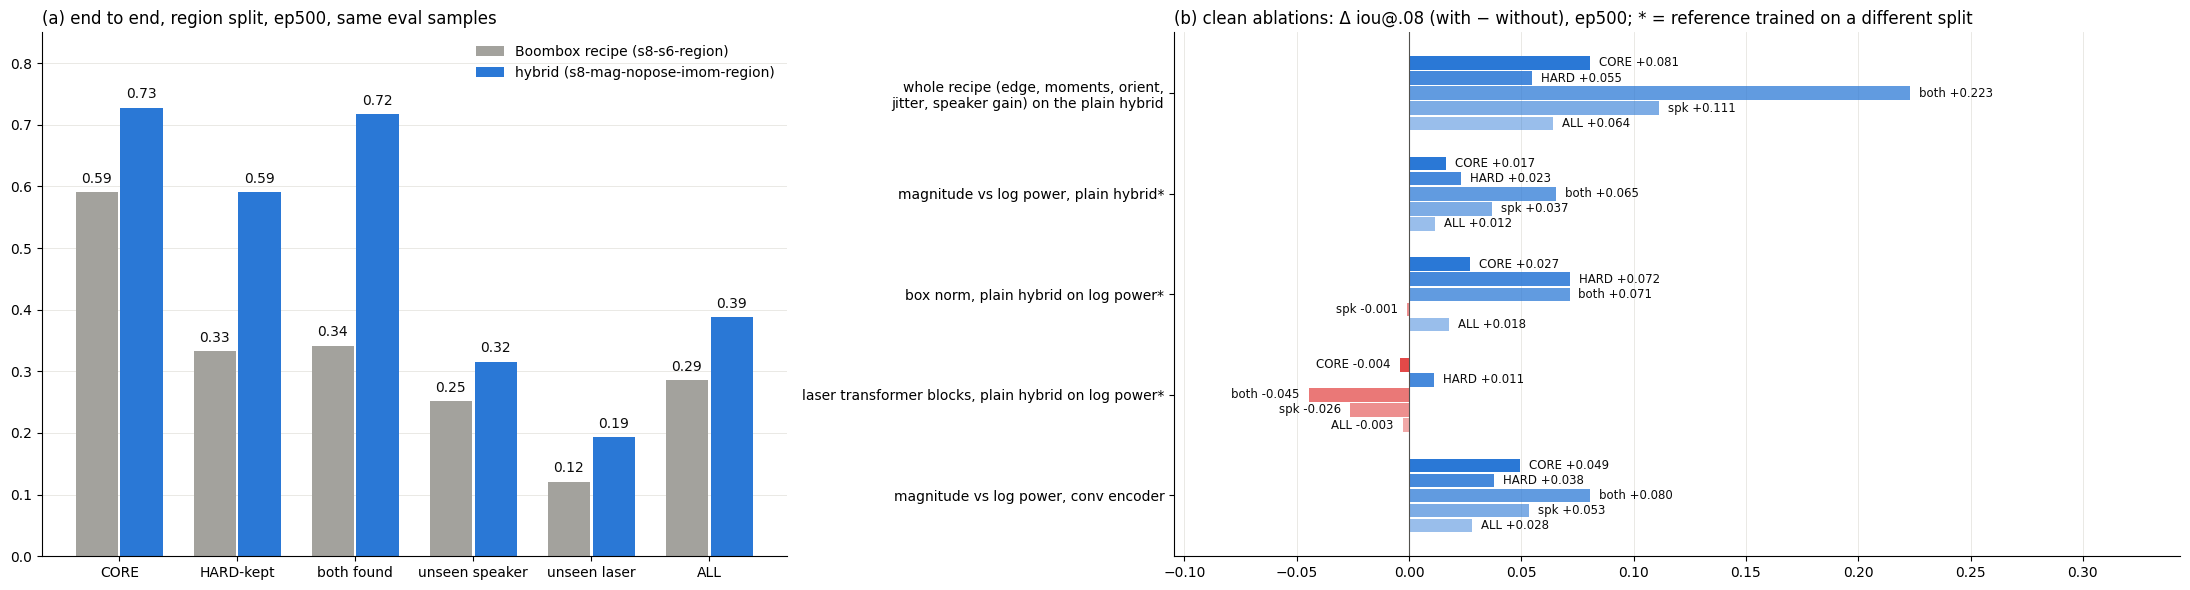

In [5]:
K = [('CORE', 'CORE'), ('HARD', 'HARD-kept'), ('both', 'both found'), ('spk', 'unseen speaker'), ('laser', 'unseen laser'), ('ALL', 'ALL')]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(22, 6), gridspec_kw=dict(width_ratios=[1, 1.35]))
xx = np.arange(len(K)); w = 0.36
for j, (name, color) in enumerate(zip(pair.index, [NEUTRAL, UP])):
    vals = pair.loc[name, [k for k, _ in K]].to_numpy(float)
    a1.bar(xx + (j - 0.5) * (w + 0.02), vals, width=w, color=color, label=name, zorder=2)
    for xi, vi in zip(xx, vals): a1.text(xi + (j - 0.5) * (w + 0.02), vi + 0.01, f'{vi:.2f}', ha='center', va='bottom', fontsize=10, color=INK)
a1.set_xticks(xx, [t for _, t in K]); a1.set_ylim(0, 0.85); a1.legend(frameon=False, loc='upper right', fontsize=10)
a1.set_title('(a) end to end, region split, ep500, same eval samples', loc='left', fontsize=12)
yy = np.arange(len(abl))[::-1]; h = 0.15
cols = ['CORE', 'HARD', 'both', 'spk', 'ALL']
for j, c in enumerate(cols):
    vals = abl[c].to_numpy()
    a2.barh(yy + (2 - j) * h, vals, height=h * 0.9, color=[UP if v >= 0 else DOWN for v in vals], alpha=1 - 0.13 * j, zorder=2)
    for yi, vi in zip(yy, vals): a2.text(vi + (0.004 if vi >= 0 else -0.004), yi + (2 - j) * h, f'{c} {vi:+.3f}', va='center', ha='left' if vi >= 0 else 'right', fontsize=8.5, color=INK)
a2.axvline(0, color=MUTED, lw=0.8); a2.set_yticks(yy, abl.index, fontsize=10)
a2.set_title('(b) clean ablations: Δ iou@.08 (with − without), ep500; * = reference trained on a different split', loc='left', fontsize=12)
a2.set_xlim(abl[cols].to_numpy().min() - 0.06, abl[cols].to_numpy().max() + 0.12)
for ax in (a1, a2):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.grid(axis='x' if ax is a2 else 'y', color='#e6e5e0', lw=0.6, zorder=0); ax.set_axisbelow(True)
fig.tight_layout(); plt.show()

## 4 What it adds up to

- **CORE .590 → .742 (+.152), HARD .371 → .584, both found .40 → .78, ALL .323 → .412.** The Boombox at its full 3000 epochs is .615 / .385 / .40 / .335, so the gain isn't a longer schedule.
- **Largest single CORE step: the ModalFormer encoder + box norm**, +.066 over the conv encoder on log power. Most of it is box norm: +.027 in the clean log-power ablation, against −.004 for the laser transformer blocks.
- **The input signal was a detour.** Log power cost the conv model −.049 CORE and −.053 unseen speaker. Going back to magnitude on the hybrid gave +.016 CORE and **+.076 unseen speaker**, the biggest speaker step.
- **Losses:** edge + moments gave +.027 CORE and +.026 HARD. The pose branch gave +.019 CORE and +.027 HARD, and took HARD rotation error from 31° to 23°.
- **The pose branch is the multi-object killer.** Removing it costs nothing on CORE, but both-found goes .36 → .71, and per-instance moments then take it to .78. Laser jitter collapsed two-object scenes (both found .37 → .006: it draws one object). Speaker gain partly recovered that (.29).
- **Augmentations:** jitter +.017 CORE, +.031 HARD, +.057 unseen laser. Speaker gain +.017 CORE, +.035 unseen speaker.
- **Like for like on the region split:** CORE +.138, HARD +.259, both found .34 → .72, unseen speaker +.065, unseen laser +.073, ALL +.101.
- **What we're left with** is the Boombox's decoder and aux heads with three changes:
  - a box-normalized, band-token encoder: 19 band tokens per laser, gated, then 2 transformer blocks over the lasers;
  - outline, per-instance moment and orientation losses;
  - two physics-shaped augmentations (speaker gain, laser jitter).

**Gaps and caveats:**
- No run adds tukey alone to the Boombox: step 1 also changes the schedule (3000 → 500 ep) and the split (src6 → orig).
- No run adds box norm without the ModalFormer encoder. The conv encoder ignores `--box-norm`.
- Encoder and box norm, pose and orient, and edge and moment were each added together.
- `nolaser-r2` and `nobn-r2` are on the wedge split while their reference `hybrid-base` is on the original split. CORE on the 1781 samples every run shares matches each run's own CORE within .005 (`runs/lineage_112.csv`), so the split effect on CORE is small.
- Single seeds throughout, so steps under ~.01 are noise.